In [65]:
batch_n = 100
in_features = 3
out_features = 1
epoch_n = 100
learning_rate = 0.001

In [66]:
import torch

In [67]:
# y = 3x_1 + 5x_2 + 1x_3
x = torch.rand(batch_n, in_features)
x

tensor([[0.4303, 0.4739, 0.7123],
        [0.4263, 0.0411, 0.6117],
        [0.7459, 0.2393, 0.8768],
        [0.8422, 0.2031, 0.1484],
        [0.9330, 0.5620, 0.9078],
        [0.2248, 0.4828, 0.3445],
        [0.7000, 0.5023, 0.1838],
        [0.1853, 0.1385, 0.7377],
        [0.9836, 0.5821, 0.4794],
        [0.6345, 0.2913, 0.1198],
        [0.7490, 0.6961, 0.3706],
        [0.0984, 0.2409, 0.0013],
        [0.6128, 0.2468, 0.9692],
        [0.0111, 0.2196, 0.0627],
        [0.1844, 0.7235, 0.9698],
        [0.8848, 0.7840, 0.0682],
        [0.7022, 0.9052, 0.6226],
        [0.0793, 0.9766, 0.0996],
        [0.6863, 0.1323, 0.6837],
        [0.9093, 0.8617, 0.5706],
        [0.4583, 0.4210, 0.5561],
        [0.0350, 0.8817, 0.7575],
        [0.1780, 0.0521, 0.4435],
        [0.7093, 0.8872, 0.8991],
        [0.9566, 0.7440, 0.9875],
        [0.1272, 0.3759, 0.9818],
        [0.9515, 0.1687, 0.4782],
        [0.3672, 0.7618, 0.7945],
        [0.1214, 0.0326, 0.6115],
        [0.370

In [68]:
c = torch.tensor([[3.0], [5.0], [1.0]])
c

tensor([[3.],
        [5.],
        [1.]])

In [69]:
y = x.mm(c)
y = y.add(torch.rand(batch_n, out_features))
y

tensor([[4.6080],
        [2.2380],
        [4.9665],
        [3.7896],
        [7.0578],
        [4.3111],
        [5.3842],
        [2.0184],
        [6.4487],
        [4.1898],
        [6.4753],
        [2.0379],
        [4.6787],
        [1.8174],
        [5.3034],
        [7.5670],
        [7.8295],
        [6.0817],
        [3.8509],
        [8.2619],
        [4.1852],
        [6.1871],
        [1.9439],
        [8.0809],
        [8.0985],
        [3.8552],
        [5.1221],
        [6.5165],
        [1.1407],
        [5.5727],
        [6.1532],
        [5.9046],
        [6.7776],
        [3.7803],
        [4.7076],
        [7.3461],
        [6.5941],
        [4.8321],
        [3.7687],
        [4.0018],
        [7.1036],
        [5.9615],
        [6.4384],
        [6.4405],
        [3.9219],
        [6.1858],
        [5.1490],
        [8.6399],
        [4.2229],
        [4.9557],
        [5.4901],
        [6.5647],
        [4.8152],
        [5.0438],
        [3.0331],
        [8

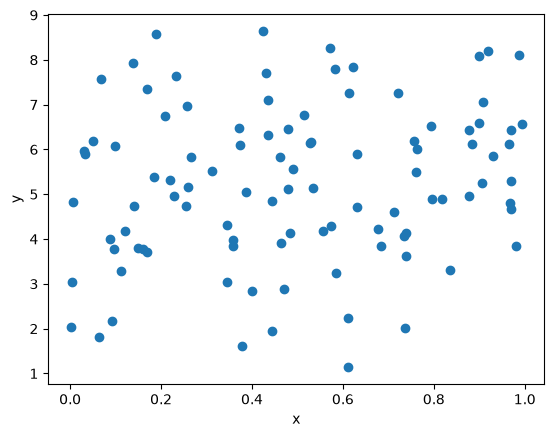

In [70]:
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(x[:, 2], y)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [71]:
w = torch.rand(
    in_features,
    out_features,
)
w

tensor([[0.3482],
        [0.4229],
        [0.7207]])

### 土法煉鋼

In [72]:
for epoch in range(epoch_n):
    y_predict = x.mm(w)
    loss = (y_predict - y).pow(2).sum()
    print("Epoch:{}, Loss:{}".format(epoch, loss))
    
    grand_y_predict = 2 * (y_predict - y)
    grand_w = x.t().mm(grand_y_predict)
    
    w -= learning_rate * grand_w

Epoch:0, Loss:2240.41845703125
Epoch:1, Loss:1540.8328857421875
Epoch:2, Loss:1067.176025390625
Epoch:3, Loss:746.2731323242188
Epoch:4, Loss:528.656005859375
Epoch:5, Loss:380.8830261230469
Epoch:6, Loss:280.3465576171875
Epoch:7, Loss:211.7628173828125
Epoch:8, Loss:164.79934692382812
Epoch:9, Loss:132.4705047607422
Epoch:10, Loss:110.05327606201172
Epoch:11, Loss:94.35440063476562
Epoch:12, Loss:83.21453857421875
Epoch:13, Loss:75.17339324951172
Epoch:14, Loss:69.24329376220703
Epoch:15, Loss:64.75599670410156
Epoch:16, Loss:61.25932312011719
Epoch:17, Loss:58.447044372558594
Epoch:18, Loss:56.111732482910156
Epoch:19, Loss:54.1126594543457
Epoch:20, Loss:52.354286193847656
Epoch:21, Loss:50.77158737182617
Epoch:22, Loss:49.3201904296875
Epoch:23, Loss:47.969688415527344
Epoch:24, Loss:46.699180603027344
Epoch:25, Loss:45.494117736816406
Epoch:26, Loss:44.34431457519531
Epoch:27, Loss:43.2425537109375
Epoch:28, Loss:42.183597564697266
Epoch:29, Loss:41.16355895996094
Epoch:30, Loss:

In [73]:
w

tensor([[3.4114],
        [4.9340],
        [1.5832]])

### Auto grad

In [74]:
from torch.autograd import Variable

In [ ]:
Vx = Variable(x, requires_grad=False)
Vy = Variable(y, requires_grad=False)
Vw = Variable(torch.rand(in_features, out_features), requires_grad=True)

In [76]:
for epoch in range(epoch_n):
    y_predict = Vx.mm(Vw)
    loss = (y_predict - Vy).pow(2).sum()
    print("Epoch:{}, Loss:{}".format(epoch, loss))

    loss.backward()

    Vw.data -= learning_rate * Vw.grad.data
    
    Vw.grad.data.zero_()

Epoch:0, Loss:4291.904296875
Epoch:1, Loss:2938.1845703125
Epoch:2, Loss:2021.947265625
Epoch:3, Loss:1401.49072265625
Epoch:4, Loss:981.0211181640625
Epoch:5, Loss:695.779541015625
Epoch:6, Loss:501.9870300292969
Epoch:7, Loss:370.0472106933594
Epoch:8, Loss:279.9517517089844
Epoch:9, Loss:218.1736297607422
Epoch:10, Loss:175.56744384765625
Epoch:11, Loss:145.9498291015625
Epoch:12, Loss:125.13976287841797
Epoch:13, Loss:110.30998229980469
Epoch:14, Loss:99.54829406738281
Epoch:15, Loss:91.56117248535156
Epoch:16, Loss:85.47339630126953
Epoch:17, Loss:80.6925048828125
Epoch:18, Loss:76.81717681884766
Epoch:19, Loss:73.575439453125
Epoch:20, Loss:70.78263854980469
Epoch:21, Loss:68.31332397460938
Epoch:22, Loss:66.08199310302734
Epoch:23, Loss:64.03018188476562
Epoch:24, Loss:62.11775207519531
Epoch:25, Loss:60.316986083984375
Epoch:26, Loss:58.608558654785156
Epoch:27, Loss:56.97880935668945
Epoch:28, Loss:55.417991638183594
Epoch:29, Loss:53.918975830078125
Epoch:30, Loss:52.47645187

In [77]:
Vw.data

tensor([[3.3007],
        [4.9423],
        [1.6942]])